# 01 · Colab·LLM 코딩과 분자 데이터 다루기
### 실습으로 배우는 신약개발 AI — 강의 목차 ①~③ 연계

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/01_Colab_LLM_Molecules.ipynb)

| 항목 | 내용 |
|---|---|
| **목차 연계** | ① 신약개발 프로세스와 AI · ② 화합물 데이터 다루기(SMILES와 분자 표현형) · ③ LLM 코딩으로 만드는 AI 모델 |
| **학습 목표** | Colab 사용법, LLM에게 코드를 시키는 워크플로우, SMILES·RDKit으로 분자를 숫자(특성)로 바꾸는 법 |
| **데이터** | ESOL(Delaney) 용해도 데이터 1,128개 분자 (MoleculeNet 공개) |
| **실행 환경** | CPU 런타임 · 약 15분 |

> **핵심 메시지**: AI 모델은 숫자만 이해합니다. 신약개발 AI의 첫 단계는 **분자를 숫자(표현형, representation)로 바꾸는 것**이고,
> 코드는 **LLM(Gemini·Claude·ChatGPT)** 에게 맡기고 우리는 **문제 정의와 결과 검증**에 집중합니다.

## 0. Colab 기초
- 브라우저에서 실행되는 **무료 파이썬 환경** (구글 계정 필요), 무료 GPU 사용 가능
- 셀 실행: 셀 클릭 후 **`Shift + Enter`** (또는 왼쪽 ▶ 버튼)
- 라이브러리가 없으면 `%pip install 이름` 한 줄로 설치
- 메뉴 **[런타임] → [런타임 유형 변경]** 에서 GPU(T4) 선택 가능
- 화면 오른쪽 위/셀 안의 **Gemini 버튼**으로 코드 생성·설명·오류 수정을 바로 요청할 수 있습니다

In [1]:
# ⚙️ 실습 환경 준비 (처음 한 번 실행, 약 30초)
%pip install -q rdkit koreanize-matplotlib
import koreanize_matplotlib                      # 그래프 한글 폰트 자동 설정
import sys, platform
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from rdkit import RDLogger; RDLogger.DisableLog("rdApp.*")
print("파이썬 버전:", sys.version.split()[0])
print("✅ 준비 완료")

Note: you may need to restart the kernel to use updated packages.


파이썬 버전: 3.12.13
✅ 준비 완료


In [2]:
# 지금 GPU 가 붙어 있는지 확인 (없어도 이 노트북은 CPU 로 충분합니다)
try:
    import torch
    print("GPU 사용 가능:", torch.cuda.is_available())
except ImportError:
    print("torch 미설치 — 이 노트북에서는 필요 없습니다")

GPU 사용 가능: False


## 1. 신약 데이터 처음 열어보기 (pandas)
**ESOL(Delaney) 용해도 데이터**는 신약개발 AI에서 가장 많이 쓰이는 공개 데이터입니다.
- 각 행 = 하나의 화합물
- `smiles` : 분자를 글자로 표현한 것
- `measured log solubility in mols per litre` : 실제 측정한 용해도(logS). 약이 되려면 물에 적당히 녹아야 합니다.

In [3]:
url = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv"
df = pd.read_csv(url)
df = df.rename(columns={"measured log solubility in mols per litre": "logS"})
print("데이터 크기 (행, 열):", df.shape)
df.head()

데이터 크기 (행, 열): (1128, 10)


,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,logS,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


In [4]:
# 열 목록과 숫자 열의 요약 통계 — 데이터를 '눈으로' 먼저 확인하는 습관
print(list(df.columns))
df.describe().round(2)

['Compound ID', 'ESOL predicted log solubility in mols per litre', 'Minimum Degree', 'Molecular Weight', 'Number of H-Bond Donors', 'Number of Rings', 'Number of Rotatable Bonds', 'Polar Surface Area', 'logS', 'smiles']


,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,logS
count,1128.00,1128.00,1128.00,1128.00,1128.00,1128.00,1128.00,1128.00
mean,-2.99,1.06,203.94,0.70,1.39,2.18,34.87,-3.05
std,1.68,0.24,102.74,1.09,1.32,2.64,35.38,2.10
min,-9.70,0.00,16.04,0.00,0.00,0.00,0.00,-11.60
25%,-3.95,1.00,121.18,0.00,0.00,0.00,0.00,-4.32
50%,-2.87,1.00,182.18,0.00,1.00,1.00,26.30,-2.86
75%,-1.84,1.00,270.37,1.00,2.00,3.00,55.44,-1.60
max,1.09,2.00,780.95,11.00,8.00,23.00,268.68,1.58


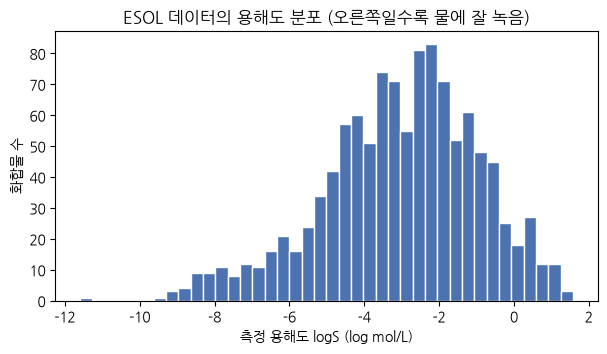

In [5]:
plt.figure(figsize=(7, 3.5))
plt.hist(df["logS"], bins=40, color="#4C72B0", edgecolor="white")
plt.xlabel("측정 용해도 logS (log mol/L)"); plt.ylabel("화합물 수")
plt.title("ESOL 데이터의 용해도 분포 (오른쪽일수록 물에 잘 녹음)")
plt.show()

## 2. ⭐ 핵심 워크플로우: LLM에게 코드를 시키기
파이썬 문법을 몰라도 됩니다. **원하는 것을 정확히 말로 설명**하면 LLM이 코드를 써 줍니다.

```
문제 정의 → 프롬프트 작성 → LLM 코드 생성 → Colab 실행 → 결과 검증 → (오류/수정 요청 반복)
```

### 좋은 프롬프트의 4요소
| 요소 | 예시 |
|---|---|
| **① 역할·맥락** | "너는 친절한 파이썬 데이터 분석 튜터야. 나는 파이썬 초보 제약 연구원이야." |
| **② 데이터 설명** | "df 데이터프레임에 'Compound ID', 'smiles', 'logS' 열이 있어." |
| **③ 구체적 요청** | "용해도가 가장 낮은 화합물 10개를 표로 보여줘." |
| **④ 형식·제약** | "한글 주석을 달고, 그래프는 matplotlib 로 그려줘." |

### 예시 프롬프트 (복사해서 Gemini/Claude 에 붙여 보세요)
```
너는 친절한 파이썬 데이터 분석 튜터야. 나는 파이썬을 처음 배우는 제약 연구원이야.
pandas 데이터프레임 df 가 있고 열은 'Compound ID', 'smiles', 'logS' 야.
logS 가 가장 낮은(물에 안 녹는) 화합물 10개를 골라 Compound ID 와 logS 만 표로 출력해줘.
코드에는 한글 주석을 달아줘.
```

In [6]:
# 👇 LLM 이 만들어 줄 법한 코드 — 실행해서 결과가 말이 되는지 '검증'합니다
worst10 = df.sort_values("logS", ascending=True).head(10)   # 오름차순 정렬 후 10개
worst10[["Compound ID", "logS"]]

,Compound ID,logS
603,"2,2',3,3',4,4',5,5',6,6'-PCB",-11.600
718,Coronene,-9.332
297,"2,2',3,3',4,4',5,5'-PCB",-9.160
60,"2,2',3,3',5,5',6,6'-PCB",-9.150
676,Benzo[ghi]perylene,-9.018
879,"2,2',3,4,5,5',6-PCB",-8.940
220,Perylene,-8.804
871,"2,2',4,4',6,6'-PCB",-8.710
637,Benzo(a)pyrene,-8.699
54,"2,2',3,3',5,6-PCB",-8.600


### 🔁 실습: 여러분 차례입니다
아래 빈 셀에 LLM 에게 받은 코드를 붙여 넣고 실행해 보세요.
1. "용해도가 가장 **높은** 화합물 5개를 보여줘"
2. "SMILES 글자 길이를 `len` 열로 추가하고, `len` 과 `logS` 의 산점도를 그려줘"

> **검증 습관**: LLM 코드는 반드시 실행해서 결과를 확인합니다. 에러가 나면 **에러 메시지를 그대로 붙여 넣고 "이 에러 고쳐줘"** 라고 요청하세요.
> LLM 은 그럴듯하지만 틀린 코드(존재하지 않는 함수, 잘못된 열 이름)를 만들 수 있습니다 → **결과 검증은 사람의 몫**입니다.

In [7]:
# ✏️ 여기에 LLM 에게 받은 코드를 붙여 넣고 실행하세요

## 3. SMILES — 분자를 글자로 표현하기
**SMILES**(Simplified Molecular-Input Line-Entry System)는 분자 구조를 한 줄의 문자열로 적는 규칙입니다.

| 표기 | 의미 | 예 |
|---|---|---|
| `C`, `N`, `O` | 원자 (수소는 생략) | `CCO` = 에탄올 |
| `=`, `#` | 이중·삼중 결합 | `C=O` (카보닐) |
| `( )` | 가지(분기) | `CC(C)O` = 이소프로판올 |
| 숫자 | 고리 열고 닫기 | `C1CCCCC1` = 사이클로헥산 |
| 소문자 | 방향족 원자 | `c1ccccc1` = 벤젠 |

**RDKit** 은 제약사·바이오텍이 표준으로 쓰는 오픈소스 화학정보학 라이브러리로, SMILES 를 읽어 구조를 그리고 수백 가지 특성을 계산합니다.

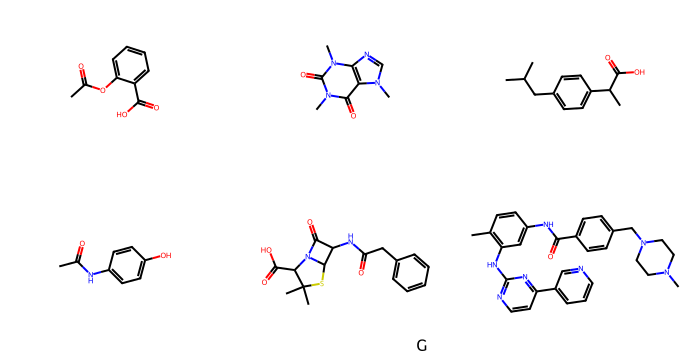

In [8]:
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, Crippen, QED, DataStructs, rdFingerprintGenerator

drugs = {
    "아스피린"  : "CC(=O)Oc1ccccc1C(=O)O",
    "카페인"    : "CN1C=NC2=C1C(=O)N(C(=O)N2C)C",
    "이부프로펜": "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
    "파라세타몰": "CC(=O)Nc1ccc(O)cc1",
    "페니실린G" : "CC1(C)SC2C(NC(=O)Cc3ccccc3)C(=O)N2C1C(=O)O",
    "이마티닙"  : "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1",
}
mols = [Chem.MolFromSmiles(s) for s in drugs.values()]
Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(230, 180), legends=list(drugs.keys()))

In [9]:
# 같은 분자라도 SMILES 는 여러 가지로 쓸 수 있습니다 → '표준(canonical) SMILES'로 통일
for s in ["OCC", "C(O)C", "CCO"]:
    print(f"{s:6s} → canonical: {Chem.MolToSmiles(Chem.MolFromSmiles(s))}")

# 문법이 틀린 SMILES 는 None 이 됩니다 (데이터 정제 단계에서 반드시 확인)
print("잘못된 SMILES:", Chem.MolFromSmiles("C1CC(C"))

OCC    → canonical: CCO
C(O)C  → canonical: CCO
CCO    → canonical: CCO
잘못된 SMILES: None


## 4. ⭐ 분자 표현형(Representation) 3가지
AI 모델은 그림이나 글자를 직접 이해하지 못합니다. 분자를 **숫자**로 바꾸는 대표적인 방법 3가지:

| 표현형 | 형태 | 장점 | 주로 쓰는 모델 |
|---|---|---|---|
| **① 분자 기술자 (Descriptor)** | 분자량·LogP·TPSA 등 수치 표 | 해석이 쉬움 | 선형회귀, 랜덤포레스트 |
| **② 분자 지문 (Fingerprint)** | 부분구조 유무를 0/1 비트로 | 유사도 계산, QSAR 에 강력 | RF, XGBoost, MLP |
| **③ 그래프 (Graph)** | 원자=노드, 결합=엣지 | 구조 정보 보존 | GNN(그래프 신경망) |
| (④ 문자열·임베딩) | SMILES 토큰 → 벡터 | 사전학습 모델 활용 | RNN, Transformer (예제 05) |

In [10]:
# ① 분자 기술자 (Descriptor): 분자를 '숫자 표' 로
def describe(name, smi):
    m = Chem.MolFromSmiles(smi)
    return {"분자": name,
            "분자량(MW)": round(Descriptors.MolWt(m), 1),
            "LogP(지용성)": round(Crippen.MolLogP(m), 2),
            "TPSA(극성표면적)": round(Descriptors.TPSA(m), 1),
            "HBD(수소결합 주개)": Descriptors.NumHDonors(m),
            "HBA(수소결합 받개)": Descriptors.NumHAcceptors(m),
            "회전결합": Descriptors.NumRotatableBonds(m),
            "방향족고리": Descriptors.NumAromaticRings(m)}

desc = pd.DataFrame([describe(n, s) for n, s in drugs.items()])
desc

,분자,분자량(MW),LogP(지용성),TPSA(극성표면적),HBD(수소결합 주개),HBA(수소결합 받개),회전결합,방향족고리
0,아스피린,180.2,1.31,63.6,1,3,2,1
1,카페인,194.2,-1.03,61.8,0,3,0,2
2,이부프로펜,206.3,3.07,37.3,1,1,4,1
3,파라세타몰,151.2,1.35,49.3,2,2,1,1
4,페니실린G,334.4,0.86,86.7,2,4,4,1
5,이마티닙,493.6,4.59,86.3,2,7,7,4


In [11]:
# RDKit 은 200개가 넘는 기술자를 한 번에 계산할 수 있습니다
all_desc = Descriptors.CalcMolDescriptors(Chem.MolFromSmiles(drugs["아스피린"]))
print("계산 가능한 기술자 수:", len(all_desc))
print("예시 10개:", list(all_desc.items())[:10])

계산 가능한 기술자 수: 217
예시 10개: [('MaxAbsEStateIndex', np.float64(10.611948223733938)), ('MaxEStateIndex', np.float64(10.611948223733938)), ('MinAbsEStateIndex', np.float64(0.01601851851851821)), ('MinEStateIndex', np.float64(-1.1140277777777776)), ('qed', 0.5501217966938848), ('SPS', 9.307692307692308), ('MolWt', 180.15899999999996), ('HeavyAtomMolWt', 172.09499999999997), ('ExactMolWt', 180.042258736), ('NumValenceElectrons', 68)]


지문 길이: 2048   켜진 비트 수: 24
켜진 비트 위치: [389, 456, 650, 695, 807, 909, 1017, 1035, 1047, 1057, 1088, 1199, 1380, 1410, 1447, 1468, 1616, 1729, 1750, 1775, 1873, 1917, 1970, 1991]


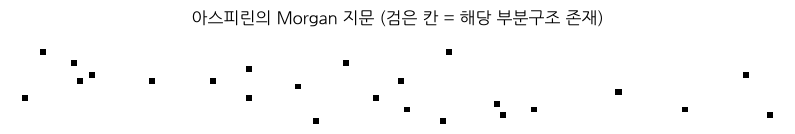

In [12]:
# ② 분자 지문 (Morgan/ECFP Fingerprint): 원자 주변 부분구조의 유무를 2048개 비트로
morgan = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fp = morgan.GetFingerprintAsNumPy(Chem.MolFromSmiles(drugs["아스피린"]))
print("지문 길이:", len(fp), "  켜진 비트 수:", fp.sum())
print("켜진 비트 위치:", np.where(fp == 1)[0].tolist())

plt.figure(figsize=(10, 1.2))
plt.imshow(fp.reshape(16, 128), cmap="Greys", aspect="auto")
plt.title("아스피린의 Morgan 지문 (검은 칸 = 해당 부분구조 존재)"); plt.axis("off"); plt.show()

In [13]:
# ③ 그래프 표현: 원자(노드) 특성 행렬 + 결합(엣지) 인접 행렬 → 예제 05 의 GNN 입력
m = Chem.MolFromSmiles("CC(=O)O")          # 아세트산 (원자 4개, 강의 슬라이드 예시)
A = Chem.GetAdjacencyMatrix(m)              # 인접 행렬: 원자 i-j 가 결합되어 있으면 1
atoms = [a.GetSymbol() for a in m.GetAtoms()]
node_feat = pd.DataFrame({"원자": atoms,
                          "원자번호": [a.GetAtomicNum() for a in m.GetAtoms()],
                          "결합 수(degree)": [a.GetDegree() for a in m.GetAtoms()],
                          "수소 수": [a.GetTotalNumHs() for a in m.GetAtoms()]})
print("인접 행렬 (Adjacency matrix):")
print(pd.DataFrame(A, index=atoms, columns=atoms))
print("\n노드 특성 행렬 (Feature matrix):")
node_feat

인접 행렬 (Adjacency matrix):
   C  C  O  O
C  0  1  0  0
C  1  0  1  1
O  0  1  0  0
O  0  1  0  0

노드 특성 행렬 (Feature matrix):


,원자,원자번호,결합 수(degree),수소 수
0,C,6,1,3
1,C,6,3,0
2,O,8,1,0
3,O,8,1,1


## 5. 약물다움(Drug-likeness): Lipinski 5원칙과 QED
- **Lipinski Rule of 5** (1997): 경구 흡수가 잘 되는 약의 경험칙 — 분자량 ≤ 500, LogP ≤ 5, HBD ≤ 5, HBA ≤ 10. **2개 이상 위반** 시 흡수 불량 가능성
- **QED** (Quantitative Estimate of Drug-likeness, 2012): 8가지 물성을 종합한 0~1 점수 (높을수록 약다움)

In [14]:
def druglike(name, smi):
    m = Chem.MolFromSmiles(smi)
    v = sum([Descriptors.MolWt(m) > 500, Crippen.MolLogP(m) > 5,
             Descriptors.NumHDonors(m) > 5, Descriptors.NumHAcceptors(m) > 10])
    return {"분자": name, "Lipinski 위반 수": v, "QED": round(QED.qed(m), 3)}

pd.DataFrame([druglike(n, s) for n, s in drugs.items()])

,분자,Lipinski 위반 수,QED
0,아스피린,0,0.550
1,카페인,0,0.538
2,이부프로펜,0,0.822
3,파라세타몰,0,0.595
4,페니실린G,0,0.798
5,이마티닙,0,0.389


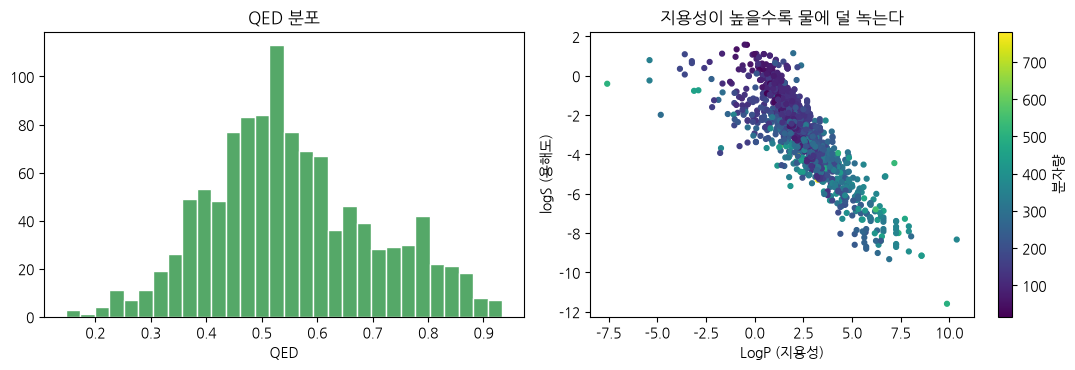

LogP 와 logS 상관계수: -0.828


In [15]:
# ESOL 전체 1,128개 분자의 QED 분포와 Lipinski 통과율
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)
df["QED"] = df["mol"].apply(QED.qed)
df["MW"] = df["mol"].apply(Descriptors.MolWt)
df["LogP"] = df["mol"].apply(Crippen.MolLogP)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df["QED"], bins=30, color="#55A868", edgecolor="white"); ax[0].set_title("QED 분포"); ax[0].set_xlabel("QED")
sc = ax[1].scatter(df["LogP"], df["logS"], c=df["MW"], cmap="viridis", s=12)
ax[1].set_xlabel("LogP (지용성)"); ax[1].set_ylabel("logS (용해도)"); ax[1].set_title("지용성이 높을수록 물에 덜 녹는다")
plt.colorbar(sc, ax=ax[1], label="분자량")
plt.tight_layout(); plt.show()
print("LogP 와 logS 상관계수:", round(df["LogP"].corr(df["logS"]), 3))

## 6. 분자 유사도(Tanimoto)와 부분구조 검색
- **Tanimoto 유사도** = 두 지문에서 (공통으로 켜진 비트) / (어느 한쪽이라도 켜진 비트), 0~1
- "구조가 비슷하면 성질도 비슷하다(유사성 원리)" → **유사물질 탐색·가상 스크리닝**의 기본 (예제 07)
- **부분구조 검색(SMARTS)**: 특정 작용기를 가진 분자만 골라내기

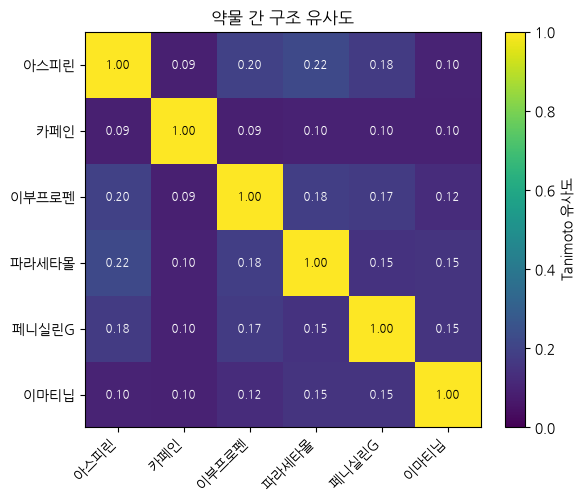

In [16]:
fps = {n: morgan.GetFingerprint(Chem.MolFromSmiles(s)) for n, s in drugs.items()}
names = list(fps)
M = np.array([[DataStructs.TanimotoSimilarity(fps[a], fps[b]) for b in names] for a in names])

plt.figure(figsize=(6, 5))
plt.imshow(M, cmap="viridis", vmin=0, vmax=1)
plt.xticks(range(len(names)), names, rotation=45, ha="right"); plt.yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        plt.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                 color="white" if M[i, j] < 0.6 else "black")
plt.colorbar(label="Tanimoto 유사도"); plt.title("약물 간 구조 유사도"); plt.tight_layout(); plt.show()

카복실산 보유 여부: {'아스피린': True, '카페인': False, '이부프로펜': True, '파라세타몰': False, '페니실린G': True, '이마티닙': False}


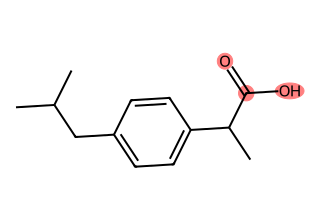

In [17]:
# 카복실산(-COOH) 을 가진 분자 찾기 (SMARTS 패턴)
pattern = Chem.MolFromSmarts("C(=O)[OH]")
hits = {n: Chem.MolFromSmiles(s).HasSubstructMatch(pattern) for n, s in drugs.items()}
print("카복실산 보유 여부:", hits)

m = Chem.MolFromSmiles(drugs["이부프로펜"])
Draw.MolToImage(m, size=(320, 220), highlightAtoms=m.GetSubstructMatch(pattern))

## 🧪 LLM 코딩 과제
아래 프롬프트를 LLM 에 넣어 코드를 받고, 실행·검증해 보세요.
```
RDKit 과 pandas 를 사용해서, df['smiles'] 의 모든 분자에 대해
Lipinski 5원칙 위반 수를 계산해 'lipinski_violations' 열로 추가하고,
위반 수별 분자 개수를 막대그래프로 그려줘. 한글 주석을 달아줘.
```

In [18]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리
| 배운 것 | 핵심 |
|---|---|
| Colab + LLM 코딩 | 문제 정의 → 프롬프트 → 실행 → **검증**. 에러는 그대로 LLM 에게 |
| SMILES | 분자를 한 줄 문자열로 표현, RDKit 으로 읽고 그림 |
| 분자 표현형 | **기술자**(해석 쉬움) · **지문**(유사도·QSAR) · **그래프**(GNN) · 임베딩(파운데이션 모델) |
| 약물다움 | Lipinski 5원칙, QED → 후보물질 1차 필터 |
| 유사도 | Tanimoto 유사도 → 유사물질 탐색, 가상 스크리닝의 출발점 |

➡️ **다음 예제 02**: 이 숫자 특성(X)으로 용해도·BBB 투과(y)를 예측하는 **머신러닝 기초 — 회귀·분류와 성능 평가**